# Linear Regression by Hand
### How does the model find its line? Let's calculate it ourselves.

Same problem as Class 18: **guess the price of a house from its size.**
But today we use only **4 houses**, so we can calculate on the whiteboard. Then we do the same in code.

At the end you will see: `model.fit()` is not magic. It is just this small calculation.

## New words

| Word | Meaning in simple words |
|------|-------------------------|
| **Independent variable** (x) | the thing we **know** and give to the model (size). It does not depend on anything here. |
| **Dependent variable** (y) | the thing we want to **guess** (price). It **depends on** the size. |
| **Slope** (β1) | how much the price goes up for **1 more marla** |
| **Intercept** (β0) | where the line starts (when size = 0) |
| **Prediction** | the price our line guesses |
| **Residual** | real price − predicted price |
| **Mean** (x̄, ȳ) | the average |

## The data: 4 houses

| House | Size in marla (x) | Price in lakh (y) |
|---|---|---|
| A | 4 | 40 |
| B | 6 | 60 |
| C | 8 | 90 |
| D | 10 | 110 |

**Question:** a new house is **12 marla**. What price will our line guess?

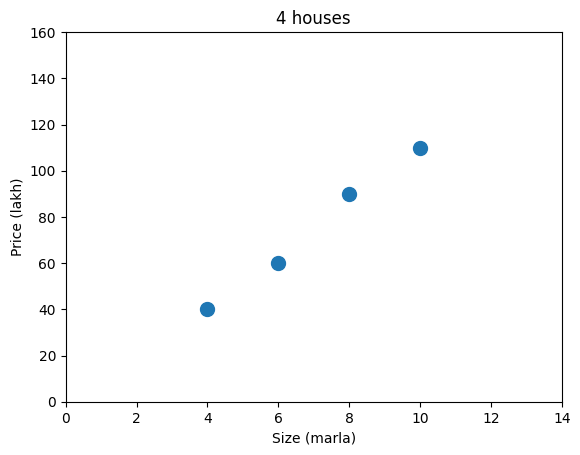

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

houses = pd.DataFrame({"size_marla": [4, 6, 8, 10], "price_lakh": [40, 60, 90, 110]},
                      index=["A", "B", "C", "D"])
size = houses["size_marla"]
price = houses["price_lakh"]

plt.scatter(size, price, s=100)
plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.title("4 houses")
plt.xlim(0, 14)
plt.ylim(0, 160)
plt.show()

## CONCEPT: Which one is independent, which one is dependent?

Ask: **"What depends on what?"**

- The price **depends on** the size. A bigger house costs more.
- The size does **not** depend on the price. A house does not become bigger because we change its price.

| | Independent variable | Dependent variable |
|---|---|---|
| Symbol | **x** | **y** |
| In our problem | **size** (marla) | **price** (lakh) |
| Meaning | the input we **know** | the output we want to **guess** |
| In Class 18 words | **feature** (`X`) | **target** (`y`) |
| On the graph | the **bottom** axis (horizontal) | the **side** axis (vertical) |

**Easy memory trick:** *x* is the **cause** (we know it). *y* is the **result** (it depends on x).

### ✏️ QUICK CHECK 0
For each pair, which is independent (x) and which is dependent (y)?
1. Study hours and exam marks
2. Age of a car and its price
3. Temperature and ice cream sales

**Answer:**
1. x = study hours, y = exam marks
2. x = age of the car, y = price
3. x = temperature, y = ice cream sales

## CONCEPT: The best straight line

- Bigger house, higher price. The dots go **up**.
- Linear Regression draws **one straight line** through the dots.
- The line has a formula:

$$\text{price} = \beta_0 + \beta_1 \times \text{size}$$

(This is the same as $y = mx + b$ from school.)

Our job: find **β1** (the slope) and **β0** (the intercept).

## The formulas (Least Squares)

$$\beta_1 = \frac{\sum (x - \bar{x})(y - \bar{y})}{\sum (x - \bar{x})^2} \qquad\qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

| Symbol | Meaning | In our code |
|--------|---------|-------------|
| $x$ | size of each house (**independent**) | `size` |
| $y$ | price of each house (**dependent**) | `price` |
| $\bar{x}$ ("x bar") | average size | `size_mean` |
| $\bar{y}$ ("y bar") | average price | `price_mean` |
| $\sum$ ("sigma") | add up for **all** houses | `.sum()` |

**In words:**
- **slope β1** = (how much size and price move **together**) ÷ (how much size moves **alone**)
- **intercept β0** = start from the average price, then go back by slope × average size

We will use these formulas in 3 steps.

## Step 1: Find the average (mean) of x and y

$$\bar{x} = \frac{4 + 6 + 8 + 10}{4} = 7 \qquad\qquad \bar{y} = \frac{40 + 60 + 90 + 110}{4} = 75$$

In [60]:
size_mean = size.mean()
price_mean = price.mean()
print("average size :", size_mean)
print("average price:", price_mean)

average size : 7.0
average price: 75.0


## Step 2: How far is each house from the average?

For every house we calculate 4 columns. They are the parts of the formula:

- $x - \bar{x}$ : how far the size is from the average size
- $y - \bar{y}$ : how far the price is from the average price
- $(x - \bar{x})(y - \bar{y})$ : multiply the two. This is the **top** of the slope formula.
- $(x - \bar{x})^2$ : square the first one. This is the **bottom** of the slope formula.

In [61]:
table = pd.DataFrame({
    "x": size,
    "y": price,
    "x - x_mean": size - size_mean,
    "y - y_mean": price - price_mean,
})
table["(x - x_mean) * (y - y_mean)"] = table["x - x_mean"] * table["y - y_mean"]
table["(x - x_mean) squared"] = table["x - x_mean"] ** 2
table

,x,y,x - x_mean,y - y_mean,(x - x_mean) * (y - y_mean),(x - x_mean) squared
A,4,40,-3.0,-35.0,105.0,9.0
B,6,60,-1.0,-15.0,15.0,1.0
C,8,90,1.0,15.0,15.0,1.0
D,10,110,3.0,35.0,105.0,9.0


In [62]:
top = table["(x - x_mean) * (y - y_mean)"].sum()
bottom = table["(x - x_mean) squared"].sum()
print("top    =", top)
print("bottom =", bottom)

top    = 240.0
bottom = 20.0


## Step 3: Slope and intercept

$$\beta_1 = \frac{\text{top}}{\text{bottom}} = \frac{240}{20} = 12 \qquad\qquad \beta_0 = \bar{y} - \beta_1 \bar{x} = 75 - 12 \times 7 = -9$$

In [63]:
b1 = top / bottom
b0 = price_mean - b1 * size_mean

print("slope (β1):", b1)
print("intercept (β0):", b0)
print("Rule: price =", b0, "+", b1, "× size")

slope (β1): 12.0
intercept (β0): -9.0
Rule: price = -9.0 + 12.0 × size


**Our line:** price = −9 + 12 × size

- Slope 12 → each extra marla adds **12 lakh**.
- Intercept −9 → the line starts at −9. A 0-marla house does not exist, so do not read it as a price. It is only where the line starts. (Same as Class 18, where it was −3.9.)

## Step 4: Draw the line

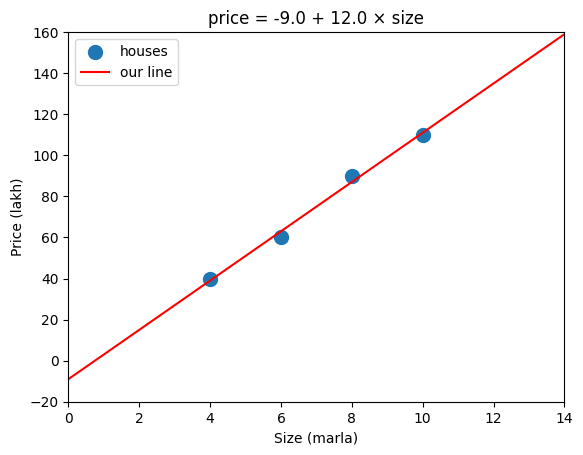

In [64]:
line_x = np.array([0, 14])
line_y = b0 + b1 * line_x

plt.scatter(size, price, s=100, label="houses")
plt.plot(line_x, line_y, color="red", label="our line")
plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.title("price = " + str(b0) + " + " + str(b1) + " × size")
plt.xlim(0, 14)
plt.ylim(-20, 160)
plt.legend()
plt.show()

## Step 5: Predict a 12 marla house

Put 12 in the formula:

$$\text{price} = -9 + 12 \times 12 = 135 \text{ lakh}$$

Predicted price for 12 marla: 135.0 lakh


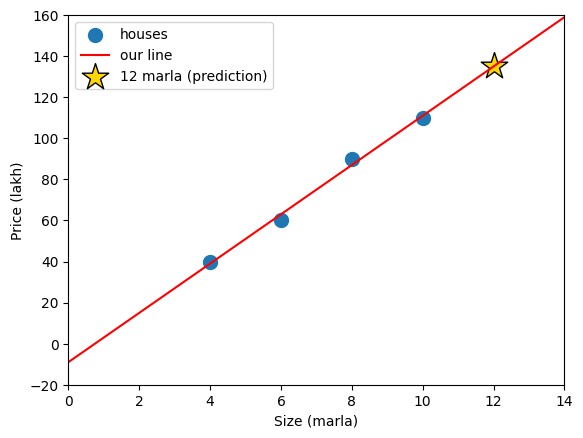

In [65]:
new_size = 12
prediction = b0 + b1 * new_size
print("Predicted price for 12 marla:", prediction, "lakh")

plt.scatter(size, price, s=100, label="houses")
plt.plot(line_x, line_y, color="red", label="our line")
plt.scatter(new_size, prediction, marker="*", s=400, color="gold", edgecolors="black", label="12 marla (prediction)")
plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.xlim(0, 14)
plt.ylim(-20, 160)
plt.legend()
plt.show()

### ✏️ QUICK CHECK 1
A house is **15 marla**. What price will our line guess?

**Answer:** −9 + 12 × 15 = **171 lakh**

## Step 6: How wrong is our line?

The line does not touch every dot. The **residual** is how far the line is from each house:

$$\text{residual} = \text{real price} - \text{predicted price}$$

The **average** size of the residuals is the **MAE** (from Class 18):

$$\text{MAE} = \frac{|r_1| + |r_2| + |r_3| + |r_4|}{4}$$

($|r|$ means: drop the minus sign.)

In [66]:
houses["predicted"] = b0 + b1 * size
houses["residual"] = houses["price_lakh"] - houses["predicted"]
houses

,size_marla,price_lakh,predicted,residual
A,4,40,39.0,1.0
B,6,60,63.0,-3.0
C,8,90,87.0,3.0
D,10,110,111.0,-1.0


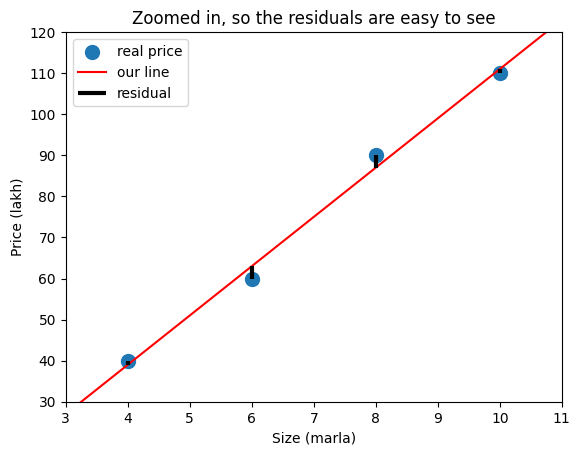

MAE: 2.0 lakh


In [67]:
plt.scatter(size, price, s=100, label="real price")
plt.plot(line_x, line_y, color="red", label="our line")
plt.vlines(size, houses["predicted"], price, color="black", linewidth=3, label="residual")
plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.title("Zoomed in, so the residuals are easy to see")
plt.xlim(3, 11)
plt.ylim(30, 120)
plt.legend()
plt.show()

mae = houses["residual"].abs().mean()
print("MAE:", mae, "lakh")

The black lines are the residuals. On average, our line is wrong by only **2 lakh**.

### ✏️ QUICK CHECK 2
House **C** is 8 marla and costs 90 lakh. What did our line predict? What is the residual? Did the model guess too high or too low?

**Answer:** predicted = −9 + 12 × 8 = **87**. Residual = 90 − 87 = **+3**. A positive residual means the model guessed **too low**.

## Step 7: Now let scikit-learn do it

Same data. Does the model find the same β0 and β1?

In [68]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(houses[["size_marla"]], houses["price_lakh"])

print("slope (β1):", round(model.coef_[0], 2))
print("intercept (β0):", round(model.intercept_, 2))
print("price for 12 marla:", round(model.predict(pd.DataFrame({"size_marla": [12]}))[0], 2))

slope (β1): 12.0
intercept (β0): -9.0
price for 12 marla: 135.0


**Same numbers: 12 and −9.**

So when we write `model.fit(...)`, the computer does exactly our table: means, differences, top ÷ bottom.
And `model.predict(...)` just puts the new size in the formula.

### ✏️ QUICK CHECK 3
Change the prices to `[40, 60, 80, 100]` (a perfect line). What are β1 and β0? Try it by hand first, then run it.

**Answer:** β1 = **10**, β0 = **0**. Every marla adds exactly 10 lakh, and all residuals are 0.

## Step 8: In a real project, we split first

**Why did we not split with 4 houses?**
- 4 houses is too few. A split would leave only 1 house to test, which tells us nothing.
- Also, we only wanted to see **how the line is calculated**.

**In a real project we always split:**
- **Train** (80%): the model learns the line from these houses.
- **Test** (20%): we keep these hidden, then check the model on them.
- The test houses are **new** to the model. So the test error is an **honest** score.

Now we use the real file with **200 houses** (the same `houses.csv` from Class 18).

**Using Colab?** Upload `houses.csv` and change the path to `"houses.csv"`.

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

all_houses = pd.read_csv("../Day 18/houses.csv")    # 200 houses
X = all_houses[["size_marla"]]
y = all_houses["price_lakh"]

# 80% to learn from, 20% to test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", len(X_train), "houses")
print("Test: ", len(X_test), "houses")

Train: 160 houses
Test:  40 houses


**Learn the line from the TRAIN houses only.** First by hand (same formula), then with scikit-learn:

In [70]:
train_size = X_train["size_marla"]

big_b1 = ((train_size - train_size.mean()) * (y_train - y_train.mean())).sum() / ((train_size - train_size.mean()) ** 2).sum()
big_b0 = y_train.mean() - big_b1 * train_size.mean()
print("By hand      → slope:", round(big_b1, 2), " intercept:", round(big_b0, 2))

real_model = LinearRegression()
real_model.fit(X_train, y_train)
print("scikit-learn → slope:", round(real_model.coef_[0], 2), " intercept:", round(real_model.intercept_, 2))

By hand      → slope: 10.45  intercept: -3.92
scikit-learn → slope: 10.45  intercept: -3.92


**Same numbers again.** Now the important part: the error on the houses the model **learned from**, and the error on the **new** houses.

Train MAE: 14.7 lakh   (houses it learned from)
Test MAE:  16.3 lakh   (new houses, the honest score)


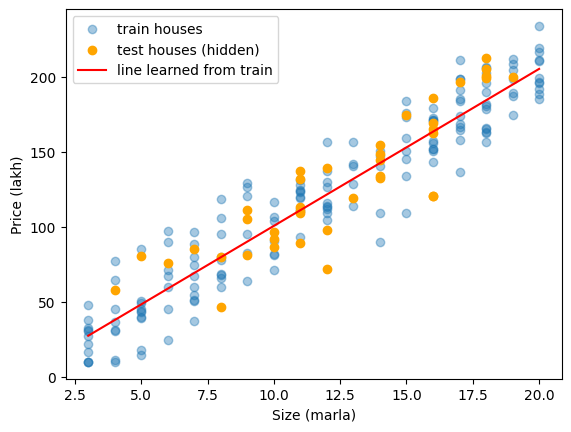

In [71]:
train_mae = mean_absolute_error(y_train, real_model.predict(X_train))
test_mae = mean_absolute_error(y_test, real_model.predict(X_test))

print("Train MAE:", round(train_mae, 1), "lakh   (houses it learned from)")
print("Test MAE: ", round(test_mae, 1), "lakh   (new houses, the honest score)")

plt.scatter(X_train["size_marla"], y_train, alpha=0.4, label="train houses")
plt.scatter(X_test["size_marla"], y_test, color="orange", label="test houses (hidden)")
sizes = pd.DataFrame({"size_marla": range(3, 21)})
plt.plot(sizes["size_marla"], real_model.predict(sizes), color="red", label="line learned from train")
plt.xlabel("Size (marla)")
plt.ylabel("Price (lakh)")
plt.legend()
plt.show()

- The line was learned from the **blue** houses only.
- The **orange** houses were hidden. We use them only to check the line.
- The **test MAE** is the number we trust. The train MAE can look better, because the model has seen those houses.

### ✏️ QUICK CHECK 4
1. Why do we keep some houses hidden?
2. Which MAE do we report to a customer: train or test?

**Answer:**
1. To check the model on **new** houses, like the real world. Otherwise we cannot know if it only memorised.
2. The **test** MAE. It is the honest one.

## The Complete Program

In [72]:
import pandas as pd
from sklearn.linear_model import LinearRegression

# 1. Data: 4 houses
houses = pd.DataFrame({"size_marla": [4, 6, 8, 10], "price_lakh": [40, 60, 90, 110]})
size = houses["size_marla"]
price = houses["price_lakh"]

# 2. By hand (Least Squares formula)
b1 = ((size - size.mean()) * (price - price.mean())).sum() / ((size - size.mean()) ** 2).sum()
b0 = price.mean() - b1 * size.mean()
print("By hand:      slope", b1, " intercept", b0, " price for 12 marla", b0 + b1 * 12)

# 3. With scikit-learn
model = LinearRegression().fit(houses[["size_marla"]], price)
print("scikit-learn: slope", round(model.coef_[0], 2), " intercept", round(model.intercept_, 2),
      " price for 12 marla", round(model.predict(pd.DataFrame({"size_marla": [12]}))[0], 2))

# 4. Real project: 200 houses, split first, then check on the hidden test houses
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

all_houses = pd.read_csv("../Day 18/houses.csv")
X = all_houses[["size_marla"]]
y = all_houses["price_lakh"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

real_model = LinearRegression().fit(X_train, y_train)
print("Train MAE:", round(mean_absolute_error(y_train, real_model.predict(X_train)), 1), "lakh")
print("Test MAE: ", round(mean_absolute_error(y_test, real_model.predict(X_test)), 1), "lakh")

By hand:      slope 12.0  intercept -9.0  price for 12 marla 135.0
scikit-learn: slope 12.0  intercept -9.0  price for 12 marla 135.0
Train MAE: 14.7 lakh
Test MAE:  16.3 lakh


## Real-World Example: many features, messy data

Our 4 houses made a clean line. Real data is not like that.
Here we predict **how much a diabetes patient's disease gets worse after 1 year**, from **10 medical measurements**, for 442 real patients.

This is one code block. Read the comments from top to bottom: **look at the data → split → train → predict → check**.

(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  progress  
0 -0.002592  0.019907 -0.017646     151.0  
1 -0.039493 -0.068332 -0.092204      75.0  
2 -0.002592  0.002861 -0.025930     141.0  
3  0.034309  0.022688 -0.009362     206.0  
4 -0.002592 -0.031988 -0.046641     135.0  


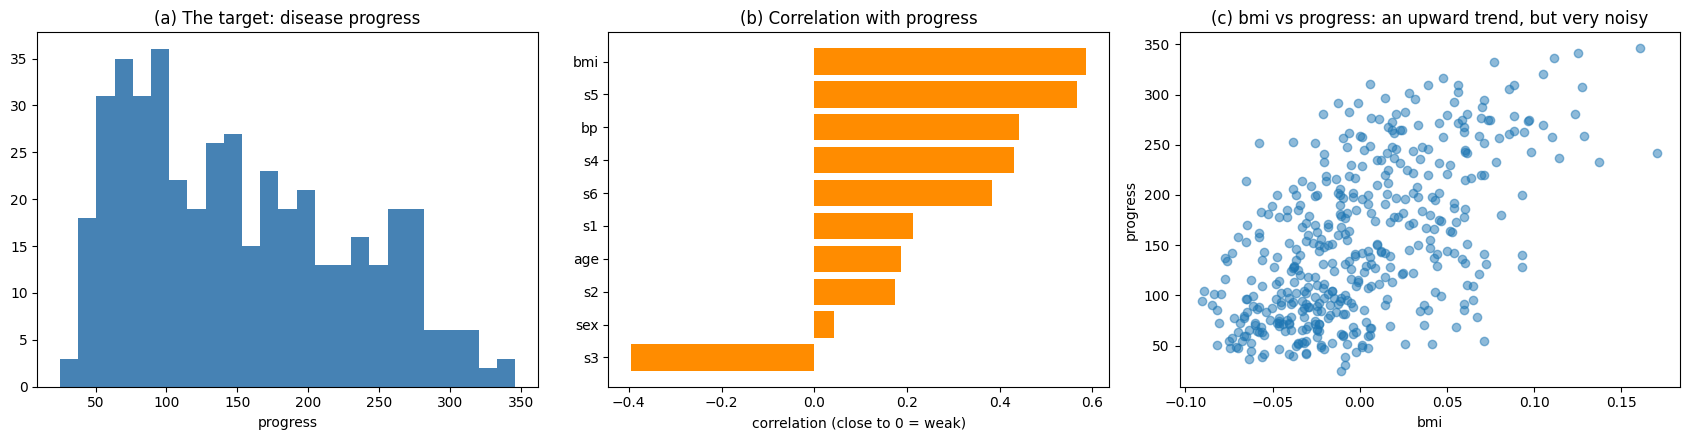

Train: 353  Test: 89

Slopes learned (one per feature):
s1    -931.0
sex   -242.0
age     38.0
s6      49.0
s3     163.0
s4     275.0
bp     348.0
s2     518.0
bmi    542.0
s5     736.0
dtype: float64
Intercept: 151.3

Lazy guess (always the average) MAE: 64.0
Our model MAE:                       42.8


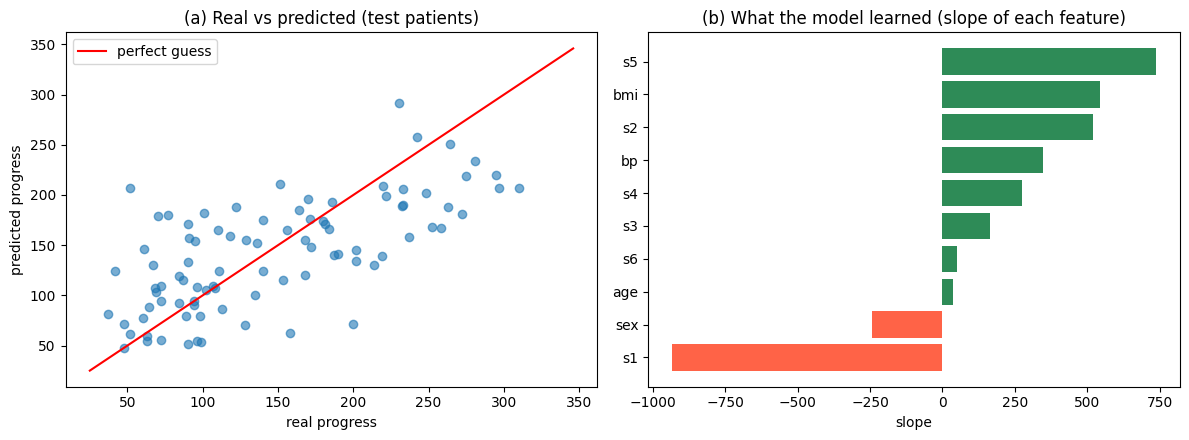


Predicted progress: 139.5
Real progress:      219.0


In [73]:
# ============================================================
# REAL-WORLD EXAMPLE: predict how a diabetes patient's disease
# gets worse after 1 year, from 10 medical measurements.
# 442 real patients. Many features, noisy data, not a perfect line.
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# ---------- 1. LOAD THE DATA ----------
# This data comes with scikit-learn, so no file is needed.
data = load_diabetes(as_frame=True)
patients = data.frame                      # 10 features + 1 target
patients = patients.rename(columns={"target": "progress"})
# NOTE: scikit-learn already scaled the features (mean 0), so you see
# small numbers like 0.05 and -0.03. That is normal. It is not a mistake.

print(patients.shape)                      # 442 patients, 11 columns
print(patients.head())

# Column meanings:
#   age, sex   : the patient
#   bmi        : body mass index (weight vs height)
#   bp         : average blood pressure
#   s1 ... s6  : blood test results (cholesterol, sugar, etc.)
#   progress   : TARGET = how much the disease got worse after 1 year (higher = worse)

# ---------- 2. VISUALIZE THE DATA FIRST ----------
# Always look at the data BEFORE choosing a model.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) What does the target look like?
axes[0].hist(patients["progress"], bins=25, color="steelblue")
axes[0].set_title("(a) The target: disease progress")
axes[0].set_xlabel("progress")

# (b) Which features go with the target? (correlation)
corr = patients.corr()["progress"].drop("progress").sort_values()
axes[1].barh(corr.index, corr.values, color="darkorange")
axes[1].set_title("(b) Correlation with progress")
axes[1].set_xlabel("correlation (close to 0 = weak)")

# (c) The strongest feature against the target
axes[2].scatter(patients["bmi"], patients["progress"], alpha=0.5)
axes[2].set_title("(c) bmi vs progress: an upward trend, but very noisy")
axes[2].set_xlabel("bmi")
axes[2].set_ylabel("progress")
plt.tight_layout()
plt.show()
# What we see: no feature gives a clean straight line like our 4 houses.
# Real data is messy. One feature alone is not enough.

# ---------- 3. SPLIT: train and test ----------
X = patients.drop(columns="progress")      # all 10 features
y = patients["progress"]                   # the target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", len(X_train), " Test:", len(X_test))

# ---------- 4. TRAIN THE MODEL ----------
model = LinearRegression()
model.fit(X_train, y_train)                # learns 1 slope for EACH of the 10 features

coefs = pd.Series(model.coef_, index=X.columns).sort_values()
print("\nSlopes learned (one per feature):")
print(coefs.round(0))
print("Intercept:", round(model.intercept_, 1))
# Positive slope = pushes progress UP (bmi, bp, s5). Negative = pushes it DOWN.
# The slopes look big because the features are tiny numbers (0.05 etc.).
# Careful: s1 and s2 are very similar blood tests, so their slopes pull against
# each other (one big minus, one big plus). In real life, do not read one slope alone.

# ---------- 5. PREDICT AND CHECK ----------
pred = model.predict(X_test)               # guesses for the 89 hidden patients

model_mae = mean_absolute_error(y_test, pred)
# A "lazy" guess: always say the average. Our model must beat this!
lazy_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

print("\nLazy guess (always the average) MAE:", round(lazy_mae, 1))
print("Our model MAE:                      ", round(model_mae, 1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) Real vs predicted. A perfect model = all dots on the red line.
axes[0].scatter(y_test, pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], color="red", label="perfect guess")
axes[0].set_xlabel("real progress")
axes[0].set_ylabel("predicted progress")
axes[0].set_title("(a) Real vs predicted (test patients)")
axes[0].legend()

# (b) Which features matter most for the model?
axes[1].barh(coefs.index, coefs.values, color=["tomato" if c < 0 else "seagreen" for c in coefs.values])
axes[1].set_title("(b) What the model learned (slope of each feature)")
axes[1].set_xlabel("slope")
plt.tight_layout()
plt.show()

# ---------- 6. PREDICT FOR ONE NEW PATIENT ----------
one_patient = X_test.iloc[[0]]             # the first test patient (double brackets = keep it a table)
print("\nPredicted progress:", round(model.predict(one_patient)[0], 1))
print("Real progress:     ", y_test.iloc[0])
# The guess is off by some distance. That is life with real data:
# the model gives a good ESTIMATE, not a perfect answer.

## Key Takeaways
- Linear Regression finds the **best straight line**: price = β0 + β1 × size.
- **Slope (β1)** = extra price for 1 more marla. **Intercept (β0)** = where the line starts.
- $\beta_1 = \dfrac{\sum (x - \bar{x})(y - \bar{y})}{\sum (x - \bar{x})^2}$ and $\beta_0 = \bar{y} - \beta_1 \bar{x}$
- **Residual** = real − predicted. **MAE** = the average size of the residuals.
- `fit()` does this calculation for us. `predict()` puts new numbers in the formula.
- In a real project, **split first**: learn from the train houses, then check on the hidden test houses. The **test** error is the honest score.